In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib, json

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

In [3]:
df = pd.read_pickle("../data/features.pkl")

features = ["amt", "amt_ratio", "hour", "is_night", "day_of_week", "age",
            "distance_km", "txn_24h", "hours_since_last", "city_pop", "category_code"]

train = df[df["split"] == "train"]
test  = df[df["split"] == "test"]
X_train, y_train = train[features], train["is_fraud"]
X_test,  y_test  = test[features],  test["is_fraud"]

print("Train:", X_train.shape, f"fraud {y_train.mean():.2%}")
print("Test: ", X_test.shape,  f"fraud {y_test.mean():.2%}")
print("Train period:", train.trans_date_trans_time.min().date(), "to", train.trans_date_trans_time.max().date())
print("Test period: ", test.trans_date_trans_time.min().date(),  "to", test.trans_date_trans_time.max().date())

Train: (1296675, 11) fraud 0.58%
Test:  (555719, 11) fraud 0.39%
Train period: 2019-01-01 to 2020-06-21
Test period:  2020-06-21 to 2020-12-31


In [4]:
def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "model": name,
        "PR-AUC": average_precision_score(y_true, proba),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "precision@0.5": precision_score(y_true, pred),
        "recall@0.5": recall_score(y_true, pred),
    }

In [5]:
numeric = [f for f in features if f != "category_code"]
prep = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["category_code"]),
])
logreg = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
logreg.fit(X_train, y_train)
proba_lr = logreg.predict_proba(X_test)[:, 1]

In [6]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Genuine per fraud:", round(ratio))

xgb = XGBClassifier(
    n_estimators=400, max_depth=6, learning_rate=0.1,
    scale_pos_weight=ratio, eval_metric="aucpr",
    tree_method="hist", n_jobs=-1, random_state=42,
)
xgb.fit(X_train, y_train)
proba_xgb = xgb.predict_proba(X_test)[:, 1]

Genuine per fraud: 172


In [7]:
results = pd.DataFrame([
    evaluate("Logistic Regression", y_test, proba_lr),
    evaluate("XGBoost", y_test, proba_xgb),
]).set_index("model").round(3)
results

,PR-AUC,ROC-AUC,precision@0.5,recall@0.5
model,,,,
Logistic Regression,0.173,0.949,0.025,0.913
XGBoost,0.910,0.998,0.521,0.926


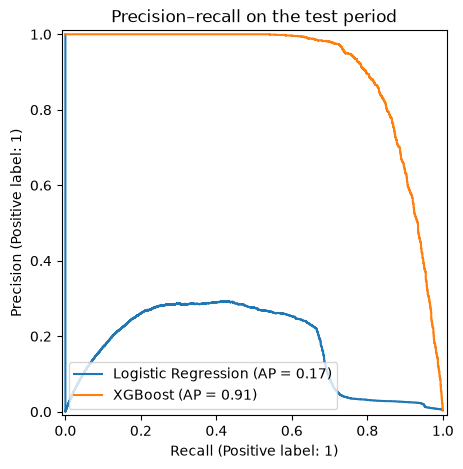

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, proba_lr, name="Logistic Regression", ax=ax)
PrecisionRecallDisplay.from_predictions(y_test, proba_xgb, name="XGBoost", ax=ax)
ax.set_title("Precision–recall on the test period")
plt.savefig("../images/pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

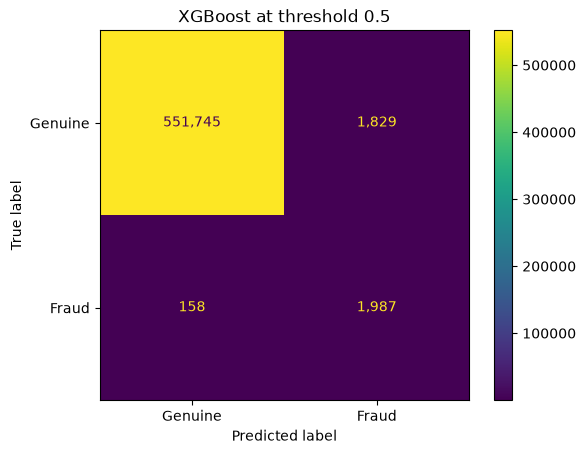

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test, (proba_xgb >= 0.5).astype(int),
    display_labels=["Genuine", "Fraud"], values_format=",")
plt.title("XGBoost at threshold 0.5")
plt.savefig("../images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
joblib.dump(xgb, "../models/fraud_xgb.joblib")
with open("../models/features.json", "w") as f:
    json.dump(features, f)

test_out = test[["amt", "is_fraud"]].copy()
test_out["proba"] = proba_xgb
test_out.to_pickle("../data/test_predictions.pkl")

In [11]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json

pred = pd.read_pickle("../data/test_predictions.pkl")
y, p, amt = pred["is_fraud"].to_numpy(), pred["proba"].to_numpy(), pred["amt"].to_numpy()
n_fraud = (y == 1).sum()

def outcomes(t, review_cost=8):
    flagged = p >= t
    caught = flagged & (y == 1)
    missed = ~flagged & (y == 1)
    false_alarms = (flagged & (y == 0)).sum()
    missed_loss = amt[missed].sum()
    review = review_cost * flagged.sum()
    return {
        "threshold": t,
        "fraud_caught_%": 100 * caught.sum() / n_fraud,
        "precision_%": 100 * caught.sum() / max(flagged.sum(), 1),
        "false_alarms": int(false_alarms),
        "false_alarms_per_1000": 1000 * false_alarms / len(y),
        "missed_fraud_$": missed_loss,
        "review_cost_$": review,
        "total_cost_$": missed_loss + review,
    }

In [12]:
thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)
table = pd.DataFrame([outcomes(t) for t in thresholds])

best = table.loc[table["total_cost_$"].idxmin()]
default = table.loc[table["threshold"] == 0.5].iloc[0]
no_model_cost = amt[y == 1].sum()      # if the bank caught nothing

summary = pd.DataFrame({"No model": {"total_cost_$": no_model_cost},
                        "Threshold 0.50": default,
                        f"Best ({best.threshold:.2f})": best}).T
summary.round(1)

,false_alarms,false_alarms_per_1000,fraud_caught_%,missed_fraud_$,precision_%,review_cost_$,threshold,total_cost_$
No model,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1133324.7
Threshold 0.50,1829.0,3.3,92.6,24560.8,52.1,30528.0,0.5,55088.8
Best (0.44),2054.0,3.7,93.4,20332.6,49.4,32464.0,0.4,52796.6


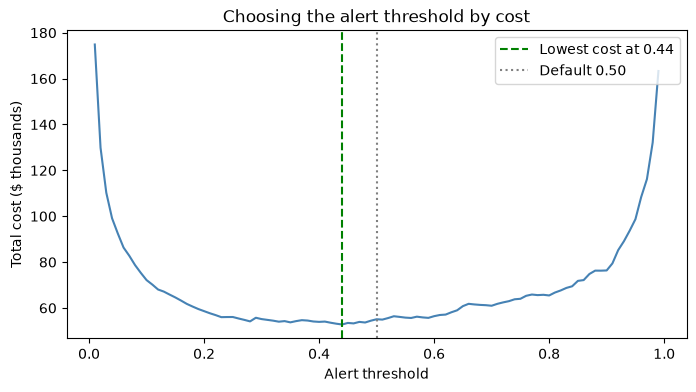

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(table["threshold"], table["total_cost_$"] / 1000, color="steelblue")
plt.axvline(best.threshold, color="green", linestyle="--", label=f"Lowest cost at {best.threshold:.2f}")
plt.axvline(0.5, color="grey", linestyle=":", label="Default 0.50")
plt.xlabel("Alert threshold"); plt.ylabel("Total cost ($ thousands)")
plt.title("Choosing the alert threshold by cost")
plt.legend()
plt.savefig("../images/threshold_cost.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
rows = []
for rc in [2, 8, 20, 50]:
    tb = pd.DataFrame([outcomes(t, rc) for t in thresholds])
    b = tb.loc[tb["total_cost_$"].idxmin()]
    rows.append({"review_cost_$": rc, "best_threshold": b.threshold,
                 "fraud_caught_%": round(b["fraud_caught_%"], 1),
                 "false_alarms_per_1000": round(b["false_alarms_per_1000"], 2)})
pd.DataFrame(rows)

,review_cost_$,best_threshold,fraud_caught_%,false_alarms_per_1000
0,2,0.23,95.4,6.25
1,8,0.44,93.4,3.70
2,20,0.59,91.9,2.69
3,50,0.90,86.1,0.92


In [15]:
with open("../models/threshold.json", "w") as f:
    json.dump({"threshold": float(best.threshold), "review_cost": 8}, f)